In [1]:
import os
import re
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import accuracy_score, f1_score, cohen_kappa_score, confusion_matrix, ConfusionMatrixDisplay
import shap

In [2]:
DATA_DIR = os.path.join(os.getcwd(), "dataset")
RESULTS_DIR = os.path.join(os.getcwd(), "results")
FIG_DIR = os.path.join(RESULTS_DIR, "figures")
os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(FIG_DIR, exist_ok=True)
RANDOM_STATE = 42

CARDIO_KEYWORDS = [
    "heart", "hypertension", "blood pressure", "cardio", "cholesterol",
    "arrhythmia", "angina", "coronary", "stroke", "diabetes", "diabetic",
    "vascular", "thrombosis", "embolism", "lipidemia", "triglyceride",
    "atrial", "smoking cessation", "obesity", "weight loss"
]

In [3]:
def sensitivity_specificity(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred)
    if cm.shape != (2, 2):
        return None, None
    tn, fp, fn, tp = cm.ravel()
    sens = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    spec = tn / (tn + fp) if (tn + fp) > 0 else 0.0
    return sens, spec

def evaluate_classifier(name, y_true, y_pred):
    acc = accuracy_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred, average="macro")
    kappa = cohen_kappa_score(y_true, y_pred)
    sens, spec = sensitivity_specificity(y_true, y_pred)
    return {"model": name, "accuracy": acc, "f1_macro": f1, "cohen_kappa": kappa, "sensitivity": sens, "specificity": spec}

def save_fig(fig, name):
    fig.savefig(os.path.join(FIG_DIR, name), bbox_inches="tight", dpi=150)

In [4]:
df_stroke_raw = pd.read_csv(os.path.join(DATA_DIR, "stroke_risk_dataset.csv"))
df_stroke_raw.shape

(70000, 18)

In [5]:
SAMPLE_SIZE = 11000
df_stroke_raw, _ = train_test_split(
    df_stroke_raw, train_size=SAMPLE_SIZE, random_state=RANDOM_STATE, stratify=df_stroke_raw["At Risk (Binary)"]
)
df_stroke_raw = df_stroke_raw.reset_index(drop=True)
df_stroke_raw.shape

(11000, 18)

In [6]:
df_stroke_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 11000 entries, 0 to 10999
Data columns (total 18 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Chest Pain                      11000 non-null  int64  
 1   Shortness of Breath             11000 non-null  int64  
 2   Irregular Heartbeat             11000 non-null  int64  
 3   Fatigue & Weakness              11000 non-null  int64  
 4   Dizziness                       11000 non-null  int64  
 5   Swelling (Edema)                11000 non-null  int64  
 6   Pain in Neck/Jaw/Shoulder/Back  11000 non-null  int64  
 7   Excessive Sweating              11000 non-null  int64  
 8   Persistent Cough                11000 non-null  int64  
 9   Nausea/Vomiting                 11000 non-null  int64  
 10  High Blood Pressure             11000 non-null  int64  
 11  Chest Discomfort (Activity)     11000 non-null  int64  
 12  Cold Hands/Feet                 11000 non-n

In [7]:
df_stroke_raw.describe()

,Chest Pain,Shortness of Breath,Irregular Heartbeat,Fatigue & Weakness,Dizziness,Swelling (Edema),Pain in Neck/Jaw/Shoulder/Back,Excessive Sweating,Persistent Cough,Nausea/Vomiting,High Blood Pressure,Chest Discomfort (Activity),Cold Hands/Feet,Snoring/Sleep Apnea,Anxiety/Feeling of Doom,Age,Stroke Risk (%),At Risk (Binary)
count,11000.000000,11000.000000,11000.000000,11000.000000,11000.000000,11000.000000,11000.000000,11000.000000,11000.000000,11000.000000,11000.000000,11000.000000,11000.000000,11000.000000,11000.000000,11000.000000,11000.000000,11000.000000
mean,0.508000,0.501182,0.505182,0.496000,0.498545,0.502636,0.503727,0.501273,0.496636,0.500909,0.501182,0.507000,0.499455,0.496909,0.500636,54.002636,55.597636,0.649182
std,0.499959,0.500021,0.499996,0.500007,0.500021,0.500016,0.500009,0.500021,0.500011,0.500022,0.500021,0.499974,0.500022,0.500013,0.500022,21.015904,14.342739,0.477248
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,18.000000,10.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,36.000000,45.500000,0.000000
50%,1.000000,1.000000,1.000000,0.000000,0.000000,1.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,0.000000,0.000000,1.000000,54.000000,55.500000,1.000000
75%,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,72.000000,66.000000,1.000000
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,90.000000,100.000000,1.000000


In [8]:
df_stroke_raw.isnull().sum()

Chest Pain                        0
Shortness of Breath               0
Irregular Heartbeat               0
Fatigue & Weakness                0
Dizziness                         0
Swelling (Edema)                  0
Pain in Neck/Jaw/Shoulder/Back    0
Excessive Sweating                0
Persistent Cough                  0
Nausea/Vomiting                   0
High Blood Pressure               0
Chest Discomfort (Activity)       0
Cold Hands/Feet                   0
Snoring/Sleep Apnea               0
Anxiety/Feeling of Doom           0
Age                               0
Stroke Risk (%)                   0
At Risk (Binary)                  0
dtype: int64

In [9]:
print("duplicate rows:", df_stroke_raw.duplicated().sum())

duplicate rows: 19


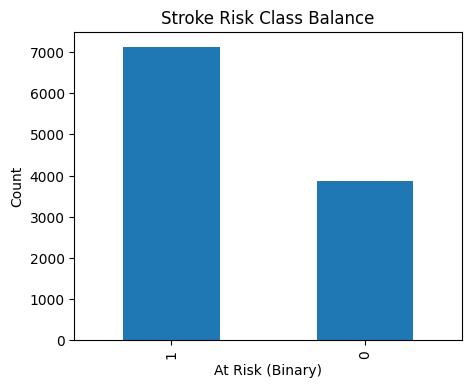

In [10]:
fig, ax = plt.subplots(figsize=(5, 4))
df_stroke_raw["At Risk (Binary)"].value_counts().plot(kind="bar", ax=ax)
ax.set_title("Stroke Risk Class Balance")
ax.set_xlabel("At Risk (Binary)")
ax.set_ylabel("Count")
save_fig(fig, "stroke_class_balance.png")
plt.show()

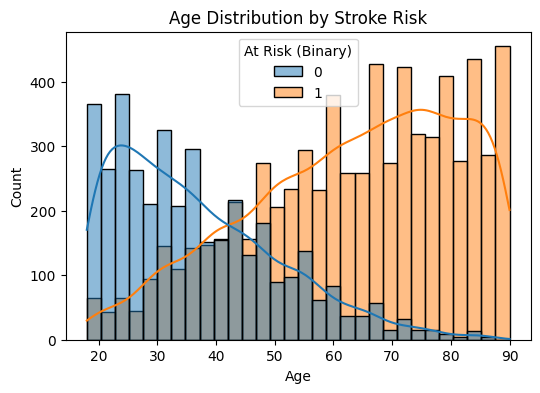

In [11]:
fig, ax = plt.subplots(figsize=(6, 4))
sns.histplot(data=df_stroke_raw, x="Age", hue="At Risk (Binary)", bins=30, kde=True, ax=ax)
ax.set_title("Age Distribution by Stroke Risk")
save_fig(fig, "stroke_age_distribution.png")
plt.show()

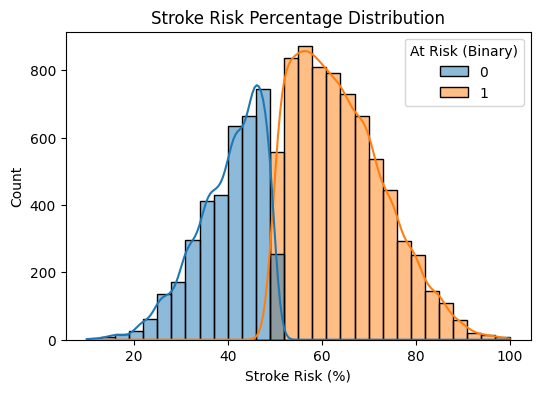

In [12]:
fig, ax = plt.subplots(figsize=(6, 4))
sns.histplot(data=df_stroke_raw, x="Stroke Risk (%)", hue="At Risk (Binary)", bins=30, kde=True, ax=ax)
ax.set_title("Stroke Risk Percentage Distribution")
save_fig(fig, "stroke_risk_pct_distribution.png")
plt.show()

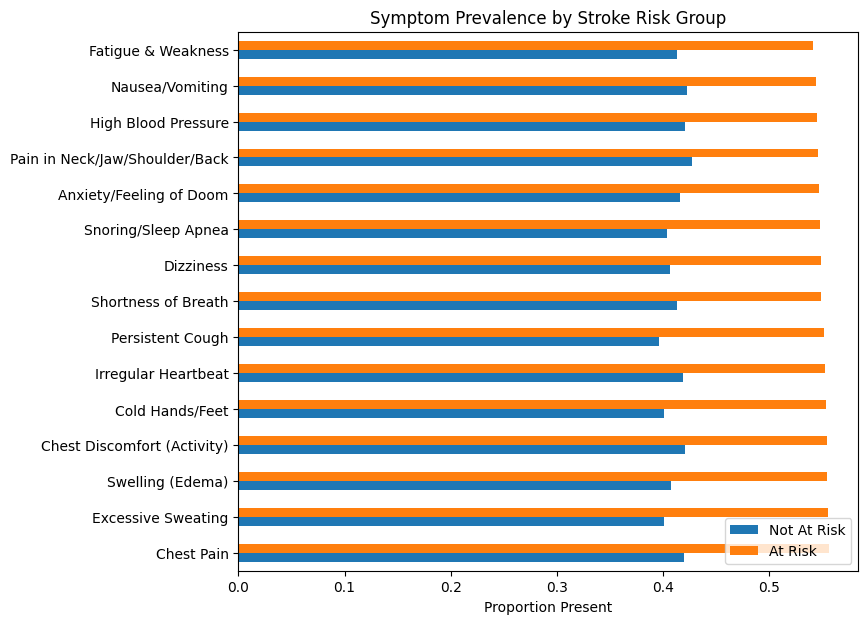

In [13]:
symptom_cols = [c for c in df_stroke_raw.columns if c not in ["Age", "Stroke Risk (%)", "At Risk (Binary)"]]
symptom_prevalence = df_stroke_raw.groupby("At Risk (Binary)")[symptom_cols].mean().T
symptom_prevalence.columns = ["Not At Risk", "At Risk"]
symptom_prevalence = symptom_prevalence.sort_values("At Risk", ascending=False)

fig, ax = plt.subplots(figsize=(8, 7))
symptom_prevalence.plot(kind="barh", ax=ax)
ax.set_title("Symptom Prevalence by Stroke Risk Group")
ax.set_xlabel("Proportion Present")
save_fig(fig, "stroke_symptom_prevalence.png")
plt.show()

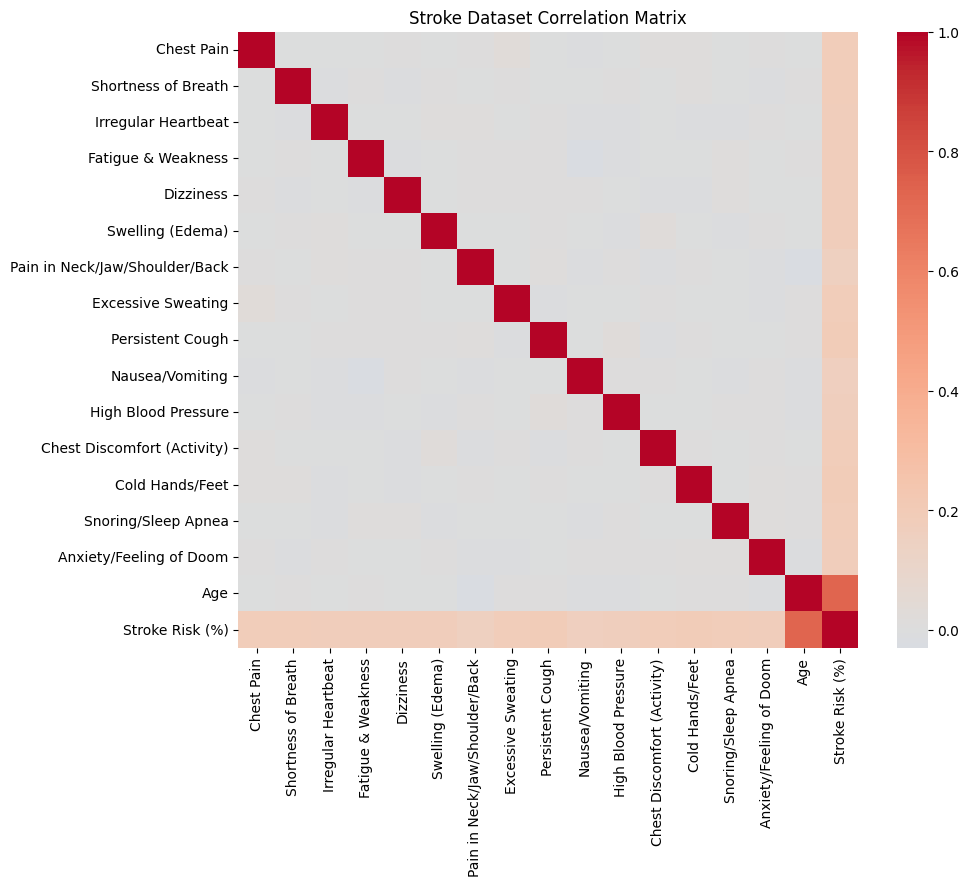

In [14]:
fig, ax = plt.subplots(figsize=(10, 8))
corr = df_stroke_raw.drop(columns=["At Risk (Binary)"]).corr()
sns.heatmap(corr, cmap="coolwarm", center=0, ax=ax)
ax.set_title("Stroke Dataset Correlation Matrix")
save_fig(fig, "stroke_correlation_matrix.png")
plt.show()

In [15]:
df_stroke = df_stroke_raw.dropna()
df_stroke = df_stroke.drop_duplicates()
df_stroke.shape

(10981, 18)

In [16]:
target_col = "At Risk (Binary)"
drop_cols = [target_col]
if "Stroke Risk (%)" in df_stroke.columns:
    drop_cols.append("Stroke Risk (%)")

X = df_stroke.drop(columns=drop_cols)
y = df_stroke[target_col]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [17]:
models = {
    "KNN": KNeighborsClassifier(n_neighbors=7),
    "DecisionTree": DecisionTreeClassifier(max_depth=8, random_state=RANDOM_STATE),
    "RandomForest": RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE),
    "SVM": SVC(kernel="rbf", probability=True, random_state=RANDOM_STATE),
}

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
stroke_results = []
fitted_models = {}
confusion_matrices = {}

for name, model in models.items():
    if name in ("KNN", "SVM"):
        model.fit(X_train_scaled, y_train)
        y_pred = model.predict(X_test_scaled)
        cv_scores = cross_val_score(model, X_train_scaled, y_train, cv=skf, scoring="f1_macro")
    else:
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)
        cv_scores = cross_val_score(model, X_train, y_train, cv=skf, scoring="f1_macro")

    res = evaluate_classifier(name, y_test, y_pred)
    res["cv_f1_macro_mean"] = float(np.mean(cv_scores))
    res["cv_f1_macro_std"] = float(np.std(cv_scores))
    stroke_results.append(res)
    fitted_models[name] = model
    confusion_matrices[name] = confusion_matrix(y_test, y_pred)

pd.DataFrame(stroke_results)

,model,accuracy,f1_macro,cohen_kappa,sensitivity,specificity,cv_f1_macro_mean,cv_f1_macro_std
0,KNN,0.893036,0.880005,0.760275,0.941795,0.802853,0.869589,0.004568
1,DecisionTree,0.842513,0.829217,0.658569,0.863955,0.802853,0.822206,0.003785
2,RandomForest,0.925353,0.916620,0.833361,0.962132,0.857328,0.916415,0.007854
3,SVM,0.975876,0.973435,0.946872,0.985273,0.958495,0.973348,0.002438


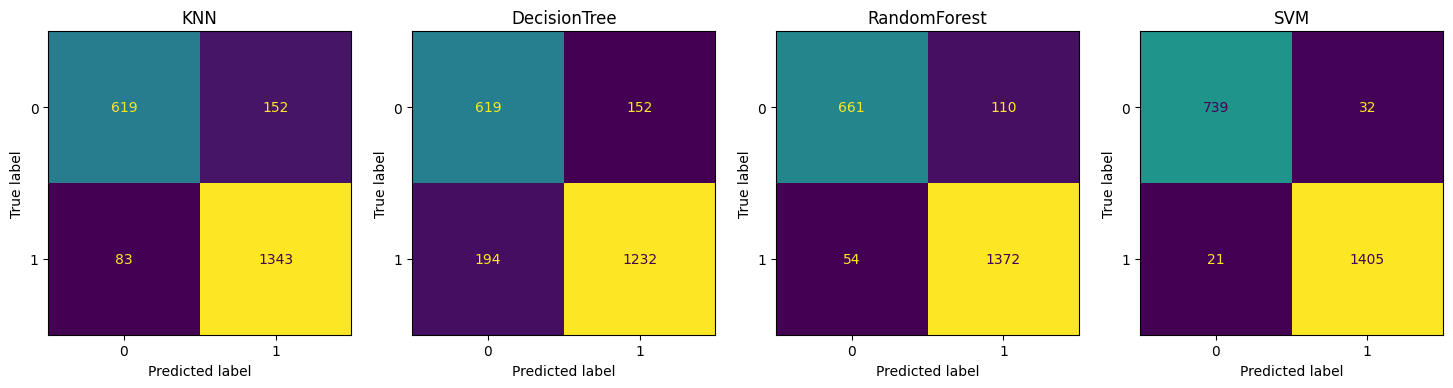

In [18]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, (name, cm) in zip(axes, confusion_matrices.items()):
    ConfusionMatrixDisplay(cm).plot(ax=ax, colorbar=False)
    ax.set_title(name)
save_fig(fig, "stroke_confusion_matrices.png")
plt.show()

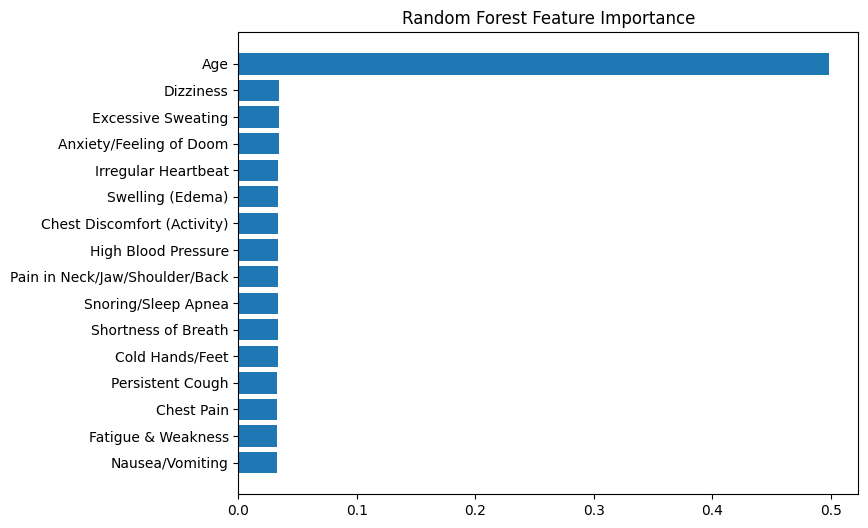

,feature,importance
0,Age,0.498498
1,Dizziness,0.034288
2,Excessive Sweating,0.034158
3,Anxiety/Feeling of Doom,0.034086
4,Irregular Heartbeat,0.033847
5,Swelling (Edema),0.033768
6,Chest Discomfort (Activity),0.033552
7,High Blood Pressure,0.033507
8,Pain in Neck/Jaw/Shoulder/Back,0.033479
9,Snoring/Sleep Apnea,0.033474


In [19]:
rf_model = fitted_models["RandomForest"]
feature_names = X.columns.tolist()
importances = rf_model.feature_importances_
importance_ranking = sorted(zip(feature_names, importances), key=lambda x: x[1], reverse=True)

fig, ax = plt.subplots(figsize=(8, 6))
names, vals = zip(*importance_ranking)
ax.barh(names[::-1], vals[::-1])
ax.set_title("Random Forest Feature Importance")
save_fig(fig, "stroke_rf_feature_importance.png")
plt.show()

pd.DataFrame(importance_ranking, columns=["feature", "importance"])

In [20]:
explainer = shap.TreeExplainer(rf_model)
shap_values = explainer.shap_values(X_test)
if isinstance(shap_values, list):
    shap_values_pos = shap_values[1]
elif shap_values.ndim == 3:
    shap_values_pos = shap_values[:, :, 1]
else:
    shap_values_pos = shap_values
mean_abs_shap = np.abs(shap_values_pos).mean(axis=0)
shap_ranking = sorted(zip(feature_names, mean_abs_shap), key=lambda x: x[1], reverse=True)
pd.DataFrame(shap_ranking, columns=["feature", "mean_abs_shap"])

,feature,mean_abs_shap
0,Age,0.256387
1,Excessive Sweating,0.050002
2,Swelling (Edema),0.049674
3,Cold Hands/Feet,0.049375
4,Dizziness,0.048197
5,Snoring/Sleep Apnea,0.047695
6,Persistent Cough,0.047338
7,Chest Pain,0.043456
8,Chest Discomfort (Activity),0.042002
9,Anxiety/Feeling of Doom,0.040177


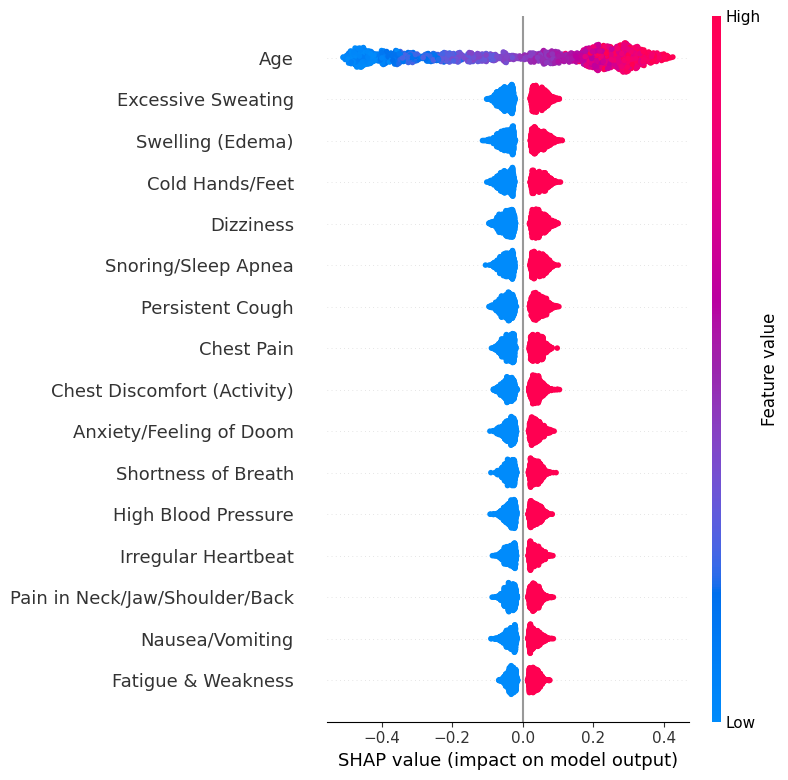

In [21]:
shap.summary_plot(shap_values_pos, X_test, feature_names=feature_names, show=False)
plt.savefig(os.path.join(FIG_DIR, "stroke_shap_summary.png"), bbox_inches="tight", dpi=150)
plt.show()

In [22]:
stroke_output = {
    "n_rows": int(len(df_stroke)),
    "n_features": int(X.shape[1]),
    "class_balance": y.value_counts(normalize=True).to_dict(),
    "model_results": stroke_results,
    "random_forest_feature_importance": [{"feature": f, "importance": float(i)} for f, i in importance_ranking],
    "shap_mean_abs_importance": [{"feature": f, "mean_abs_shap": float(i)} for f, i in shap_ranking],
}

with open(os.path.join(RESULTS_DIR, "stroke_results.json"), "w") as f:
    json.dump(stroke_output, f, indent=2, default=str)

stroke_output["model_results"]

[{'model': 'KNN',
  'accuracy': 0.8930359581247155,
  'f1_macro': 0.8800048714356999,
  'cohen_kappa': 0.7602750061870356,
  'sensitivity': 0.9417952314165497,
  'specificity': 0.8028534370946823,
  'cv_f1_macro_mean': 0.8695886043399395,
  'cv_f1_macro_std': 0.004568134221277587},
 {'model': 'DecisionTree',
  'accuracy': 0.8425125170687301,
  'f1_macro': 0.8292169919838959,
  'cohen_kappa': 0.6585692970092553,
  'sensitivity': 0.8639551192145862,
  'specificity': 0.8028534370946823,
  'cv_f1_macro_mean': 0.8222059363780462,
  'cv_f1_macro_std': 0.0037847717670272674},
 {'model': 'RandomForest',
  'accuracy': 0.9253527537551206,
  'f1_macro': 0.9166202298944204,
  'cohen_kappa': 0.833361391019937,
  'sensitivity': 0.9621318373071529,
  'specificity': 0.8573281452658884,
  'cv_f1_macro_mean': 0.9164150907775124,
  'cv_f1_macro_std': 0.007854459568967756},
 {'model': 'SVM',
  'accuracy': 0.9758761948111061,
  'f1_macro': 0.9734350264518156,
  'cohen_kappa': 0.9468715195189824,
  'sensiti

In [23]:
df_train_raw = pd.read_csv(os.path.join(DATA_DIR, "drugsComTrain_raw.csv"))
df_test_raw = pd.read_csv(os.path.join(DATA_DIR, "drugsComTest_raw.csv"))
df_drug_all = pd.concat([df_train_raw, df_test_raw], ignore_index=True)
df_drug_all.shape

(215063, 7)

In [24]:
df_drug_all.info()

<class 'pandas.DataFrame'>
RangeIndex: 215063 entries, 0 to 215062
Data columns (total 7 columns):
 #   Column       Non-Null Count   Dtype
---  ------       --------------   -----
 0   uniqueID     215063 non-null  int64
 1   drugName     215063 non-null  str  
 2   condition    213869 non-null  str  
 3   review       215063 non-null  str  
 4   rating       215063 non-null  int64
 5   date         215063 non-null  str  
 6   usefulCount  215063 non-null  int64
dtypes: int64(3), str(4)
memory usage: 112.8 MB


In [25]:
df_drug_all.isnull().sum()

uniqueID          0
drugName          0
condition      1194
review            0
rating            0
date              0
usefulCount       0
dtype: int64

In [26]:
print("duplicate reviews:", df_drug_all.duplicated(subset=["review"]).sum())

duplicate reviews: 86585


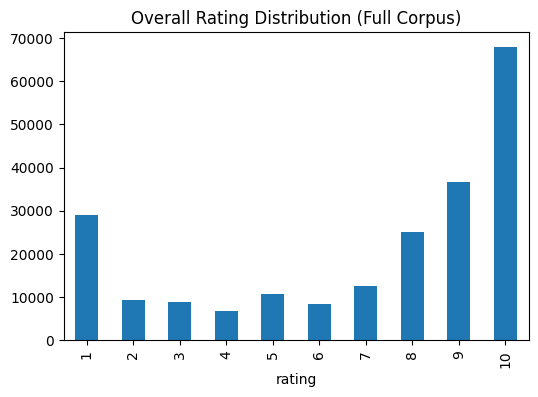

In [27]:
fig, ax = plt.subplots(figsize=(6, 4))
df_drug_all["rating"].value_counts().sort_index().plot(kind="bar", ax=ax)
ax.set_title("Overall Rating Distribution (Full Corpus)")
save_fig(fig, "drug_rating_distribution_full.png")
plt.show()

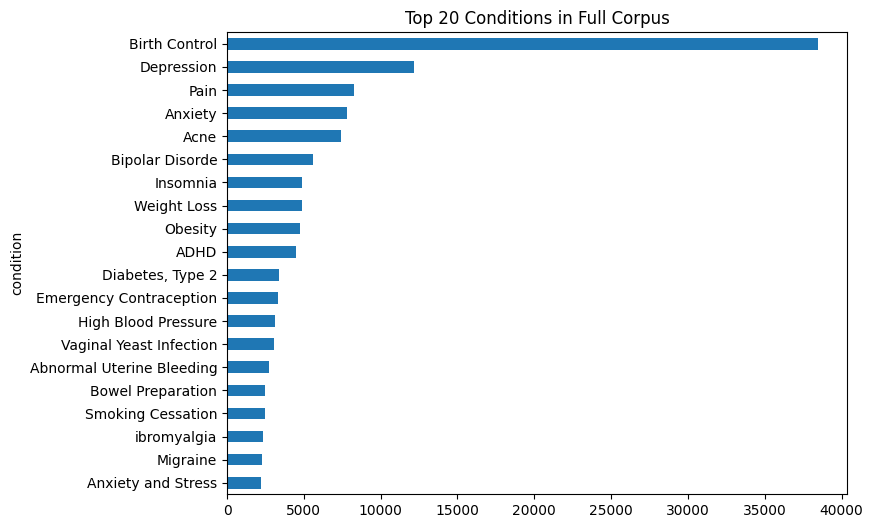

In [28]:
fig, ax = plt.subplots(figsize=(8, 6))
df_drug_all["condition"].value_counts().head(20).plot(kind="barh", ax=ax)
ax.invert_yaxis()
ax.set_title("Top 20 Conditions in Full Corpus")
save_fig(fig, "drug_top_conditions_full.png")
plt.show()

In [29]:
def clean_text(text):
    text = str(text)
    text = re.sub(r"&#\d+;", " ", text)
    text = re.sub(r"[^a-zA-Z\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip().lower()
    return text

def rating_to_sentiment(rating):
    if rating >= 7:
        return "positive"
    elif rating >= 4:
        return "neutral"
    else:
        return "negative"

In [30]:
df_drug = df_drug_all.dropna(subset=["review", "rating", "condition"]).copy()
df_drug = df_drug.drop_duplicates(subset=["review"])
df_drug["clean_review"] = df_drug["review"].apply(clean_text)
df_drug["sentiment"] = df_drug["rating"].apply(rating_to_sentiment)
df_drug["word_count"] = df_drug["clean_review"].apply(lambda x: len(x.split()))
df_drug = df_drug[df_drug["word_count"] > 3]
df_drug.shape

(127764, 10)

In [31]:
is_cardio = df_drug["condition"].str.lower().apply(lambda c: any(k in c for k in CARDIO_KEYWORDS))
df_cardio = df_drug[is_cardio].copy()
df_cardio.shape[0], df_cardio["word_count"].mean()

(13097, 82.75284416278537)

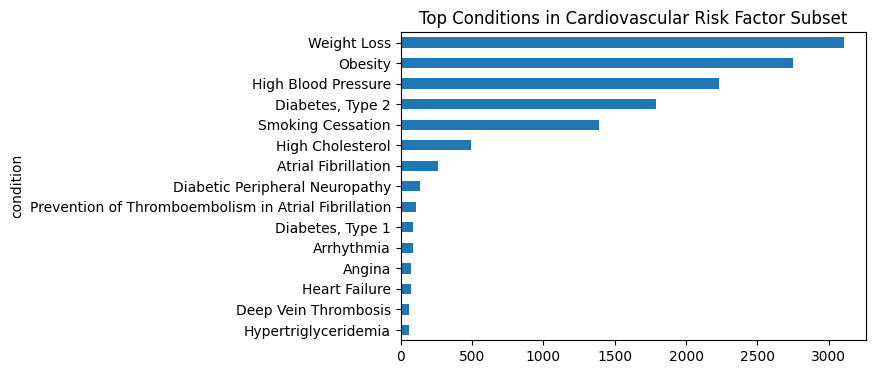

In [32]:
fig, ax = plt.subplots(figsize=(6, 4))
df_cardio["condition"].value_counts().head(15).plot(kind="barh", ax=ax)
ax.invert_yaxis()
ax.set_title("Top Conditions in Cardiovascular Risk Factor Subset")
save_fig(fig, "drug_cardio_top_conditions.png")
plt.show()

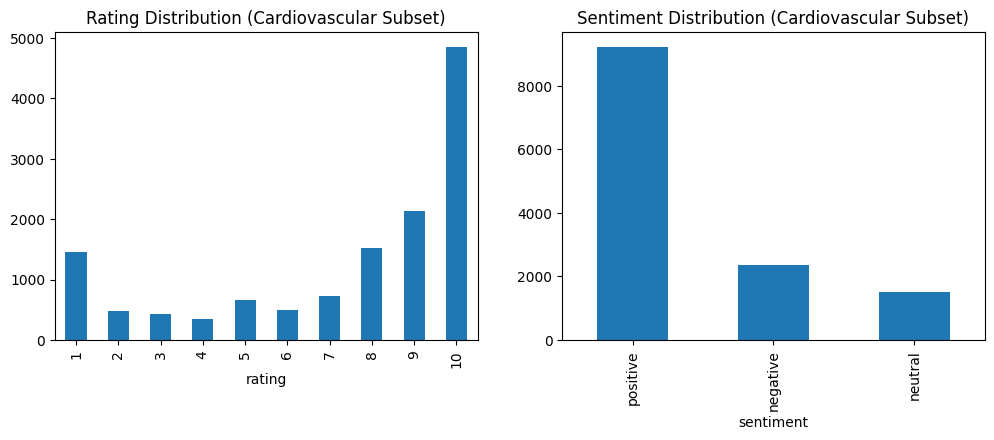

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
df_cardio["rating"].value_counts().sort_index().plot(kind="bar", ax=axes[0])
axes[0].set_title("Rating Distribution (Cardiovascular Subset)")
df_cardio["sentiment"].value_counts().plot(kind="bar", ax=axes[1])
axes[1].set_title("Sentiment Distribution (Cardiovascular Subset)")
save_fig(fig, "drug_cardio_rating_sentiment.png")
plt.show()

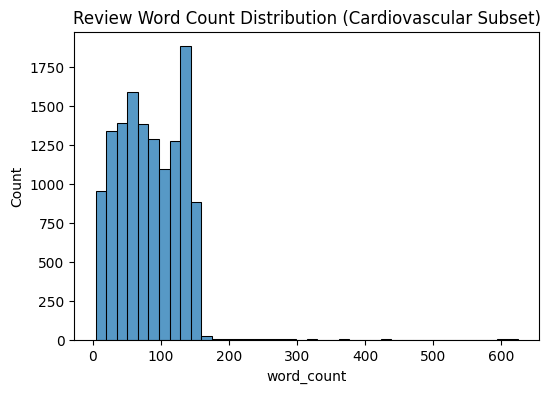

In [34]:
fig, ax = plt.subplots(figsize=(6, 4))
sns.histplot(df_cardio["word_count"], bins=40, ax=ax)
ax.set_title("Review Word Count Distribution (Cardiovascular Subset)")
save_fig(fig, "drug_cardio_word_count.png")
plt.show()

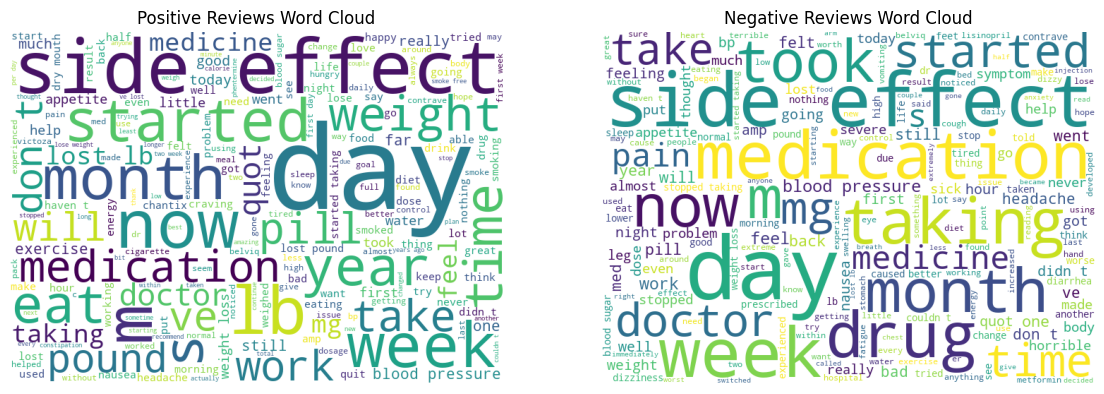

In [35]:
positive_text = " ".join(df_cardio[df_cardio["sentiment"] == "positive"]["clean_review"].sample(min(3000, (df_cardio["sentiment"] == "positive").sum()), random_state=RANDOM_STATE))
negative_text = " ".join(df_cardio[df_cardio["sentiment"] == "negative"]["clean_review"].sample(min(3000, (df_cardio["sentiment"] == "negative").sum()), random_state=RANDOM_STATE))

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
WordCloud(width=700, height=500, background_color="white").generate(positive_text).to_image()
axes[0].imshow(WordCloud(width=700, height=500, background_color="white").generate(positive_text))
axes[0].axis("off")
axes[0].set_title("Positive Reviews Word Cloud")
axes[1].imshow(WordCloud(width=700, height=500, background_color="white").generate(negative_text))
axes[1].axis("off")
axes[1].set_title("Negative Reviews Word Cloud")
save_fig(fig, "drug_cardio_wordclouds.png")
plt.show()

In [36]:
X_train_text, X_test_text, y_train_text, y_test_text = train_test_split(
    df_cardio["clean_review"], df_cardio["sentiment"], test_size=0.2, random_state=RANDOM_STATE, stratify=df_cardio["sentiment"]
)

vectorizer = TfidfVectorizer(max_features=15000, ngram_range=(1, 2), min_df=3)
X_train_vec = vectorizer.fit_transform(X_train_text)
X_test_vec = vectorizer.transform(X_test_text)
X_train_vec.shape, X_test_vec.shape

((10477, 15000), (2620, 15000))

In [37]:
nb_model = MultinomialNB()
nb_model.fit(X_train_vec, y_train_text)
nb_pred = nb_model.predict(X_test_vec)

lr_model = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
lr_model.fit(X_train_vec, y_train_text)
lr_pred = lr_model.predict(X_test_vec)

drug_results = []
drug_confusion_matrices = {}
for name, y_pred in [("NaiveBayes_TFIDF", nb_pred), ("LogisticRegression_TFIDF", lr_pred)]:
    res = evaluate_classifier(name, y_test_text, y_pred)
    del res["sensitivity"]
    del res["specificity"]
    drug_results.append(res)
    drug_confusion_matrices[name] = confusion_matrix(y_test_text, y_pred)

pd.DataFrame(drug_results)

,model,accuracy,f1_macro,cohen_kappa
0,NaiveBayes_TFIDF,0.745802,0.417539,0.235256
1,LogisticRegression_TFIDF,0.788931,0.527792,0.442498


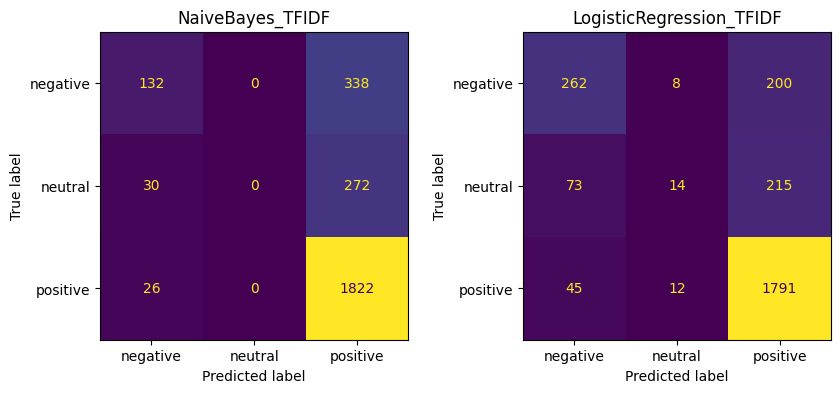

In [38]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, cm) in zip(axes, drug_confusion_matrices.items()):
    ConfusionMatrixDisplay(cm, display_labels=lr_model.classes_).plot(ax=ax, colorbar=False)
    ax.set_title(name)
save_fig(fig, "drug_confusion_matrices.png")
plt.show()

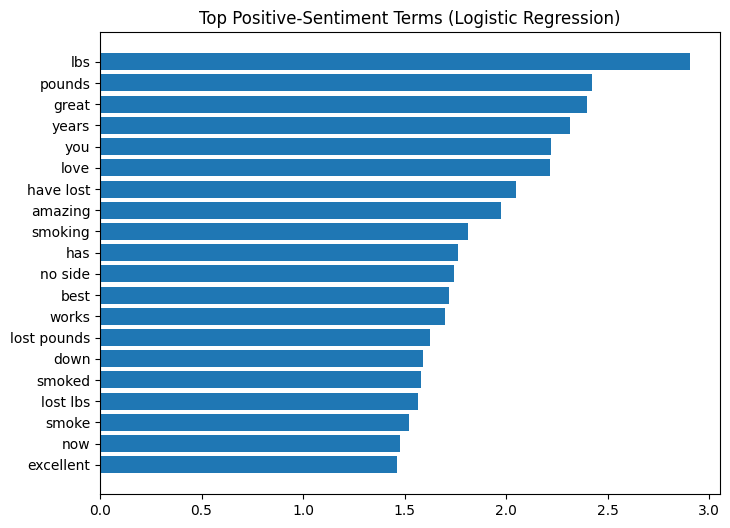

,term,coefficient
0,lbs,2.907559
1,pounds,2.420668
2,great,2.399533
3,years,2.313837
4,you,2.222057
5,love,2.214683
6,have lost,2.048389
7,amazing,1.973938
8,smoking,1.812402
9,has,1.764099


In [39]:
feature_names_text = np.array(vectorizer.get_feature_names_out())
class_index = list(lr_model.classes_).index("positive")
coefs = lr_model.coef_[class_index]
top_positive_idx = np.argsort(coefs)[-20:][::-1]
top_negative_idx = np.argsort(coefs)[:20]

top_positive_terms = [{"term": feature_names_text[i], "coefficient": float(coefs[i])} for i in top_positive_idx]
top_negative_terms = [{"term": feature_names_text[i], "coefficient": float(coefs[i])} for i in top_negative_idx]

fig, ax = plt.subplots(figsize=(8, 6))
terms = [t["term"] for t in top_positive_terms][::-1]
coef_vals = [t["coefficient"] for t in top_positive_terms][::-1]
ax.barh(terms, coef_vals)
ax.set_title("Top Positive-Sentiment Terms (Logistic Regression)")
save_fig(fig, "drug_top_positive_terms.png")
plt.show()

pd.DataFrame(top_positive_terms)

In [40]:
background = shap.sample(X_train_vec, 100, random_state=RANDOM_STATE)
text_explainer = shap.LinearExplainer(lr_model, background)
sample_test = X_test_vec[:200]
text_shap_values = text_explainer.shap_values(sample_test)
if isinstance(text_shap_values, list):
    text_shap_values_pos = text_shap_values[class_index]
elif text_shap_values.ndim == 3:
    text_shap_values_pos = text_shap_values[:, :, class_index]
else:
    text_shap_values_pos = text_shap_values
mean_abs_text_shap = np.abs(text_shap_values_pos).mean(axis=0)
mean_abs_text_shap = np.asarray(mean_abs_text_shap).ravel()
text_shap_ranking = sorted(zip(feature_names_text, mean_abs_text_shap), key=lambda x: x[1], reverse=True)[:30]
pd.DataFrame(text_shap_ranking, columns=["term", "mean_abs_shap"])

,term,mean_abs_shap
0,lbs,0.076899
1,not,0.066091
2,pounds,0.050514
3,great,0.047053
4,years,0.045465
5,you,0.042323
6,has,0.040258
7,this,0.040141
8,works,0.039409
9,no side,0.034583


In [41]:
drug_output = {
    "n_rows_cardio_subset": int(len(df_cardio)),
    "avg_word_count_cardio_subset": float(df_cardio["word_count"].mean()),
    "n_rows_full_corpus": int(len(df_drug)),
    "model_results": drug_results,
    "logistic_regression_top_positive_terms": top_positive_terms,
    "logistic_regression_top_negative_terms": top_negative_terms,
    "text_shap_top_terms": [{"term": t, "mean_abs_shap": float(v)} for t, v in text_shap_ranking],
    "top_conditions_in_subset": df_cardio["condition"].value_counts().head(15).to_dict(),
}

with open(os.path.join(RESULTS_DIR, "drug_review_results.json"), "w") as f:
    json.dump(drug_output, f, indent=2, default=str)

drug_output["model_results"]

[{'model': 'NaiveBayes_TFIDF',
  'accuracy': 0.7458015267175573,
  'f1_macro': 0.41753922487666767,
  'cohen_kappa': 0.23525575622429562},
 {'model': 'LogisticRegression_TFIDF',
  'accuracy': 0.7889312977099237,
  'f1_macro': 0.5277919008419023,
  'cohen_kappa': 0.4424982800044942}]